# Mini-Projet : Régression - Prédiction du Montant d'Achat d'une Voiture

**Objectif:** Prédire le montant d'achat d'une voiture (`amount`) à partir de:
- Le genre (gender)
- L'âge (age)
- Le salaire (salary)
- La dette (debt)
- Le patrimoine (worth)

**Dataset:** Car Purchasing Data (Kaggle)

**Modèles:** LinearRegression, RandomForestRegressor

In [40]:
# Importation des bibliotheques
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Bibliothèques importées avec succès!")

Bibliothèques importées avec succès!


In [41]:
# Chargement du dataset
data = pd.read_csv('../data/car_purchasing_data.csv')

# Afficher les premieres lignes
print("=== Premières lignes ===")
print(data.head())

# Informations
print("\n=== Informations ===")
print(data.info())

# Valeurs manquantes
print("\n=== Valeurs manquantes ===")
print(data.isnull().sum())

# Statistiques descriptives
print("\n=== Statistiques ===")
print(data.describe())

=== Premières lignes ===
     Customer Name                                    Customer e-mail Country  \
0    Martina Avila  cubilia.Curae.Phasellus@quisaccumsanconvallis.edu     USA   
1    Harlan Barnes                                eu.dolor@diam.co.uk     USA   
2  Naomi Rodriquez  vulputate.mauris.sagittis@ametconsectetueradip...     USA   
3  Jade Cunningham                            malesuada@dignissim.com     USA   
4     Cedric Leach     felis.ullamcorper.viverra@egetmollislectus.net     USA   

   gender  age       salary          debt        worth       amount  
0       0   42  62812.09301  11609.380910  238961.2505  35321.45877  
1       0   41  66646.89292   9572.957136  530973.9078  45115.52566  
2       1   43  53798.55112  11160.355060  638467.1773  42925.70921  
3       1   58  79370.03798  14426.164850  548599.0524  67422.36313  
4       1   57  59729.15130   5358.712177  560304.0671  55915.46248  

=== Informations ===
<class 'pandas.DataFrame'>
RangeIndex: 500 ent

In [42]:
# Selectionner uniquement les colonnes numeriques utiles
# On exclut: Customer Name, Customer e-mail, Country (non pertinents)
data = data[['gender', 'age', 'salary', 'debt', 'worth', 'amount']]

print("Colonnes sélectionnées!")
print(data.head())
print(f"\nShape: {data.shape}")

Colonnes sélectionnées!
   gender  age       salary          debt        worth       amount
0       0   42  62812.09301  11609.380910  238961.2505  35321.45877
1       0   41  66646.89292   9572.957136  530973.9078  45115.52566
2       1   43  53798.55112  11160.355060  638467.1773  42925.70921
3       1   58  79370.03798  14426.164850  548599.0524  67422.36313
4       1   57  59729.15130   5358.712177  560304.0671  55915.46248

Shape: (500, 6)


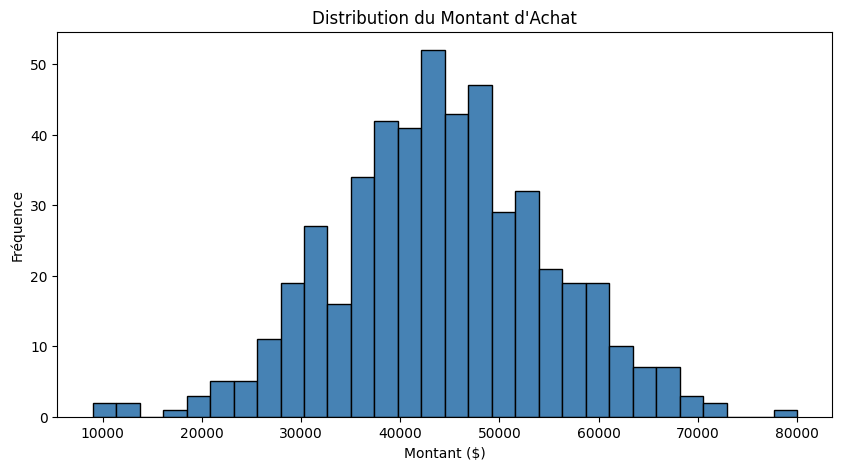

Moyenne: 44209.80
Médiane: 43997.78
Min: 9000.00
Max: 80000.00


In [43]:
# Distribution de la cible (amount)
plt.figure(figsize=(10, 5))
plt.hist(data['amount'], bins=30, color='steelblue', edgecolor='black')
plt.title('Distribution du Montant d\'Achat')
plt.xlabel('Montant ($)')
plt.ylabel('Fréquence')
plt.show()

print(f"Moyenne: {data['amount'].mean():.2f}")
print(f"Médiane: {data['amount'].median():.2f}")
print(f"Min: {data['amount'].min():.2f}")
print(f"Max: {data['amount'].max():.2f}")

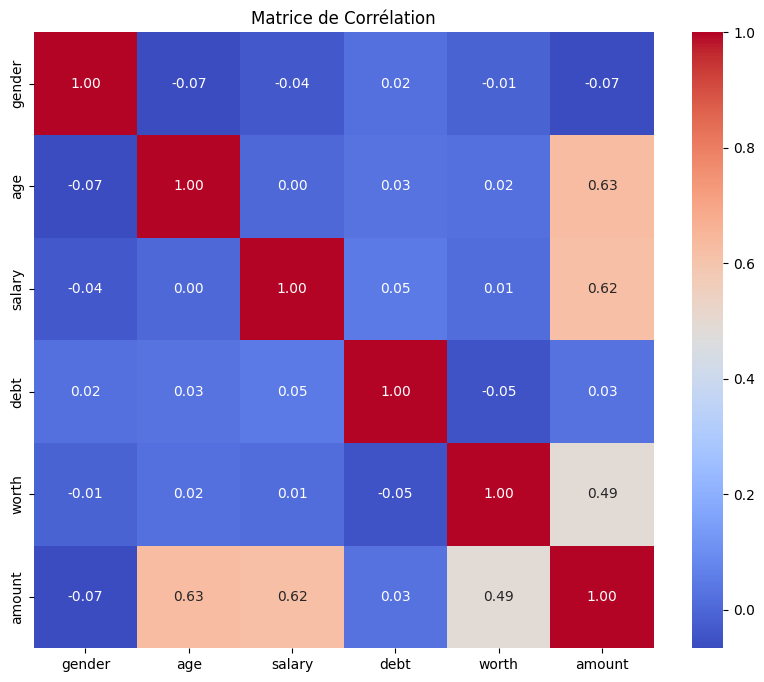

In [44]:
# Matrice de correlation
plt.figure(figsize=(10, 8))
sns.heatmap(data.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Matrice de Corrélation')
plt.show()

In [45]:
# Separation features (X) et cible (y)
X = data.drop('amount', axis=1)
y = data['amount']

print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")
print(f"\nFeatures: {list(X.columns)}")

X shape: (500, 5)
y shape: (500,)

Features: ['gender', 'age', 'salary', 'debt', 'worth']


In [46]:
# Train/Test (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"X_train: {X_train.shape}")
print(f"X_test: {X_test.shape}")
print(f"y_train: {y_train.shape}")
print(f"y_test: {y_test.shape}")

X_train: (400, 5)
X_test: (100, 5)
y_train: (400,)
y_test: (100,)


In [47]:
# Modele 1: LinearRegression
lr = LinearRegression()
lr.fit(X_train, y_train)

# Predictions
y_pred_lr = lr.predict(X_test)

# Evaluation
mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2_lr = r2_score(y_test, y_pred_lr)

print("=== LinearRegression ===")
print(f"MAE  = {mae_lr:.2f}")
print(f"RMSE = {rmse_lr:.2f}")
print(f"R²   = {r2_lr:.4f}")

# Coefficients
print(f"\nCoefficients: {lr.coef_}")
print(f"Intercept: {lr.intercept_:.2f}")

=== LinearRegression ===
MAE  = 212.72
RMSE = 249.51
R²   = 0.9994

Coefficients: [4.28270310e+01 8.39371100e+02 5.62401750e-01 8.09907086e-03
 2.89307666e-02]
Intercept: -42115.83


In [48]:
# Modele 2: RandomForestRegressor
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

# Predictions
y_pred_rf = rf.predict(X_test)

# Evaluation
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print("=== RandomForest ===")
print(f"MAE  = {mae_rf:.2f}")
print(f"RMSE = {rmse_rf:.2f}")
print(f"R²   = {r2_rf:.4f}")

=== RandomForest ===
MAE  = 1573.40
RMSE = 2262.01
R²   = 0.9526


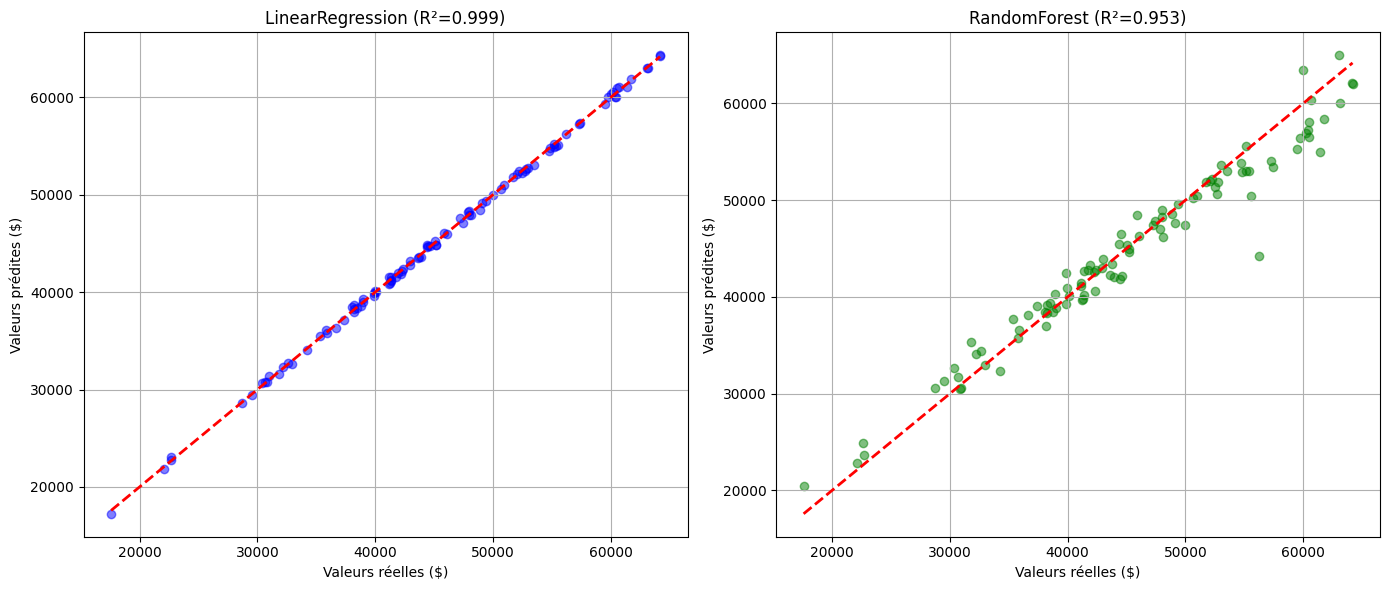

In [49]:
# Comparaison des predictions vs valeurs reelles
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# LinearRegression
axes[0].scatter(y_test, y_pred_lr, alpha=0.5, color='blue')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[0].set_xlabel('Valeurs réelles ($)')
axes[0].set_ylabel('Valeurs prédites ($)')
axes[0].set_title(f'LinearRegression (R²={r2_lr:.3f})')
axes[0].grid(True)

# RandomForest
axes[1].scatter(y_test, y_pred_rf, alpha=0.5, color='green')
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[1].set_xlabel('Valeurs réelles ($)')
axes[1].set_ylabel('Valeurs prédites ($)')
axes[1].set_title(f'RandomForest (R²={r2_rf:.3f})')
axes[1].grid(True)

plt.tight_layout()
plt.show()

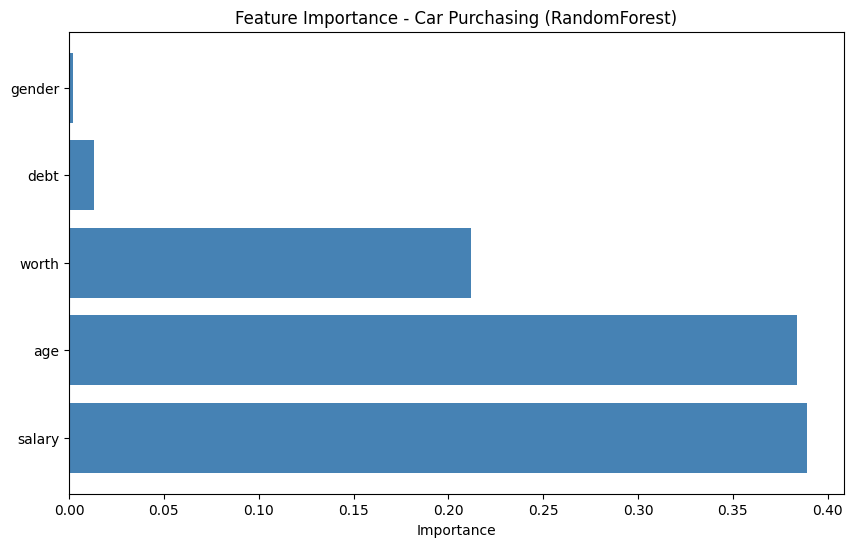

salary: 0.3891
age: 0.3840
worth: 0.2117
debt: 0.0132
gender: 0.0020


In [50]:
# Feature Importance (RandomForest)
features = X.columns
importances = rf.feature_importances_

# Trier
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(10, 6))
plt.barh([features[i] for i in indices], [importances[i] for i in indices], color='steelblue')
plt.xlabel('Importance')
plt.title('Feature Importance - Car Purchasing (RandomForest)')
plt.show()

# Affichage
for i in indices:
    print(f"{features[i]}: {importances[i]:.4f}")

In [51]:
# Comparaison
comparison = pd.DataFrame({
    'Modèle': ['LinearRegression', 'RandomForest'],
    'MAE': [mae_lr, mae_rf],
    'RMSE': [rmse_lr, rmse_rf],
    'R²': [r2_lr, r2_rf]
})

print("=== Comparaison des Modèles ===")
print(comparison.to_string(index=False))

=== Comparaison des Modèles ===
          Modèle         MAE        RMSE       R²
LinearRegression  212.721031  249.507447 0.999423
    RandomForest 1573.395852 2262.013111 0.952611


## Conclusion Critique - Mini-Projet (Car Purchasing)

### Résultats:
| Modèle | MAE | RMSE | R² |
| :--- | :--- | :--- | :--- |
| LinearRegression | 212.72 | 249.51 | 0.9994 |
| RandomForest | 1573.40 | 2262.01 | 0.9526 |

### Modèle retenu: **LinearRegression**

### Pourquoi?
- **LinearRegression** est largement plus performant (R² = 0.9994 vs 0.9526).
- MAE = 212$ (vs 1573$ pour RandomForest), ce qui est beaucoup plus faible.
- La relation entre les variables (salary, worth, debt, age) et `amount` est **linéaire**, donc LinearRegression capture parfaitement cette relation.
- RandomForest a tendance à faire de l'**overfitting** sur ce type de données.

### Variables les plus importantes:
- **Salary** (0.3891) et **Age** (0.3840) sont les variables les plus influentes.
- **Worth** (0.2117) a un impact modéré.
- **Debt** (0.0132) et **Gender** (0.0020) ont un impact très faible.

### Limites:
- Le dataset est petit (500 lignes).
- Les résultats sont presque parfaits (R²=0.9994), ce qui peut indiquer un **data leakage** ou une relation trop linéaire dans les données.

### Améliorations:
- Tester avec d'autres datasets (UCI, Kaggle).
- Ajouter plus de features (Country, Education).
- Tester d'autres modèles (XGBoost, GradientBoosting).
- Feature engineering (créer "disposable income" = salary - debt).